In [1]:
import pandas as pd
df = pd.read_csv('Synthetic_Car_Prices_10000.csv')

In [2]:
df.head()

,age,mileage_10k,engine_l,power_10hp,accident,full_service,price_pln
0,1,7,1.2,11,1,0,58014
1,10,4,2.5,13,1,1,47279
2,8,10,1.6,22,0,1,68040
3,5,12,2.5,8,1,1,49508
4,5,5,2.0,8,1,0,58299


In [3]:
X = df.drop(columns=['price_pln'])
y = df['price_pln']

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
from sklearn.linear_model import LinearRegression

In [6]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[-54001.85,-25395.31, 12347.08, 32485.65,-11266.42, 5118.2 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.824e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[44.81,44.65,31.58,27.84,27.49,27.19]"


In [7]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE: {mse:.2f} PLN^2 ")
print(f"RMSE: {rmse:.2f} PLN")
print(f"MAE:  {mae:.2f} PLN")
print(f"R^2:   {r2:.4f}")

MSE: 50988749.85 PLN^2 
RMSE: 7140.64 PLN
MAE:  5653.76 PLN
R^2:   0.9055


In [8]:
print(f"Intercept: {model.intercept_}")

coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
print(coef_df)

Intercept: 88238.82289056267
        Feature   Coefficient
0           age -54001.845554
1   mileage_10k -25395.306073
2      engine_l  12347.082008
3    power_10hp  32485.652411
4      accident -11266.422977
5  full_service   5118.196912


C:\Users\artem\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


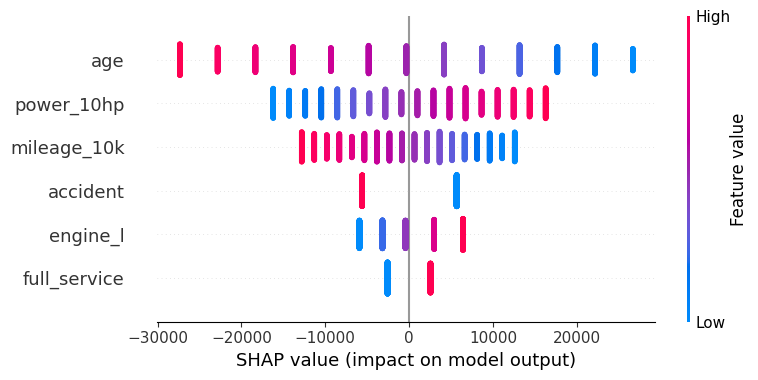

In [9]:
import shap

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

masker = shap.maskers.Independent(X_train_scaled_df, max_samples=8000)
explainer = shap.Explainer(model, masker)
shap_values = explainer(X_test_scaled_df)

shap.summary_plot(shap_values, X_test_scaled_df)

In [10]:
y_pred[0:10]

array([82560.41636799, 72808.82013344, 41040.83710877, 69121.73012894,
       45689.30968997, 72099.03460494, 33881.45903794, 75110.65343404,
       77220.10722225, 77599.57144205])

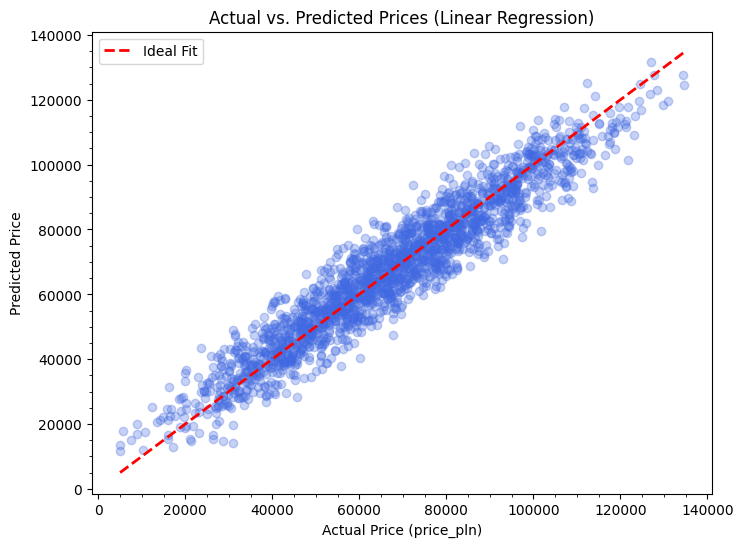

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='royalblue')

plt.minorticks_on()
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')

plt.xlabel("Actual Price (price_pln)")
plt.ylabel("Predicted Price")
plt.title("Actual vs. Predicted Prices (Linear Regression)")
plt.legend()
plt.show()

In [12]:
print(f"Predicted price: {y_pred[10]:.0f} PLN")
print(f"Actual price: {y_test.iloc[10]} PLN")

Predicted price: 74475 PLN
Actual price: 79438 PLN


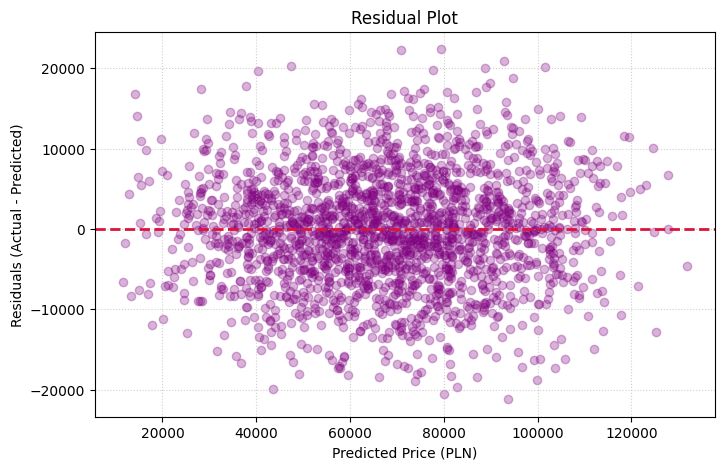

In [13]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.3, color='purple')
plt.axhline(y=0, color='crimson', linestyle='--', lw=2)
plt.xlabel("Predicted Price (PLN)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [14]:
# y_hat = 88238.82 - 54001.85*x1 - 25395.31*x2 + 12347.08*x3 + 32485.65*x4 - 11266.42*x5 + 5118.20*x6
# Here x1…x6 are age, mileage_10k, engine_l, power_10hp, accident and full_service, each scaled to [0, 1].
# A coefficient is the price change when that feature goes from its minimum to its maximum in the training data.
# The intercept is the predicted price when all features are at their minimum.

In [15]:
import numpy as np

coef_orig = model.coef_ * scaler.scale_
intercept_orig = model.intercept_ + np.sum(model.coef_ * scaler.min_)

print(f"Intercept (original units): {intercept_orig:.2f}")
for name, c in zip(X.columns, coef_orig):
    print(f"{name:13s}: {c:10.2f}")

# check: original-units equation gives the same prediction as the model
print(np.allclose(X_test.values @ coef_orig + intercept_orig, y_pred))

Intercept (original units): 68124.83
age          :   -4500.15
mileage_10k  :   -1493.84
engine_l     :    6859.49
power_10hp   :    1910.92
accident     :  -11266.42
full_service :    5118.20
True


In [16]:
# Pick 10 random test rows (by position, so we can index the scaled array)
rng = np.random.RandomState(42)
pos = rng.choice(len(X_test), size=10, replace=False)

X_sample_scaled = X_test_scaled[pos] # use the SCALED data
y_sample = y_test.iloc[pos]

# Manual prediction: y_hat = b0 + sum(b_i * x_i)
manual_preds = model.intercept_ + X_sample_scaled @ model.coef_

# Check against model.predict
model_preds = model.predict(X_sample_scaled)
print("Manual == model.predict:", np.allclose(manual_preds, model_preds))

results_df = pd.DataFrame({
    'Car / row ID': y_sample.index,
    'Actual price (PLN)': y_sample.values,
    'Predicted price (PLN)': manual_preds,
    'Difference y - y_hat (PLN)': y_sample.values - manual_preds
})
display(results_df.round(2))

Manual == model.predict: True


,Car / row ID,Actual price (PLN),Predicted price (PLN),Difference y - y_hat (PLN)
0,4343,83000,85305.50,-2305.50
1,1794,75842,70133.15,5708.85
2,708,47303,44978.84,2324.16
3,3383,76342,72913.52,3428.48
4,4534,94615,102448.83,-7833.83
5,7936,87058,88065.31,-1007.31
6,6808,100113,93197.70,6915.30
7,4607,60549,70062.13,-9513.13
8,8187,95770,93845.11,1924.89
9,6481,42731,39353.31,3377.69


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# labels: 1 is high price (>= 70000 PLN), 0 is low price
y_train_c = (y_train >= 70000).astype(int)
y_test_c = (y_test >= 70000).astype(int)

clf = LogisticRegression()
clf.fit(X_train_scaled, y_train_c)

# probability of class 1, threshold 0.5
proba = clf.predict_proba(X_test_scaled)[:, 1]
y_pred_c = (proba >= 0.5).astype(int)

print(f"Accuracy: {accuracy_score(y_test_c, y_pred_c):.4f}")
print(confusion_matrix(y_test_c, y_pred_c))
print(classification_report(y_test_c, y_pred_c, digits=3))

Accuracy: 0.9050
[[985  98]
 [ 92 825]]
              precision    recall  f1-score   support

           0      0.915     0.910     0.912      1083
           1      0.894     0.900     0.897       917

    accuracy                          0.905      2000
   macro avg      0.904     0.905     0.904      2000
weighted avg      0.905     0.905     0.905      2000



In [18]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

# --- 1) Coefficients ---
coef_c = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': clf.coef_[0],
    'Odds ratio': np.exp(clf.coef_[0])
})
print(coef_c.round(3))

# --- 2) ROC-AUC on the test set ---
print(f"ROC-AUC: {roc_auc_score(y_test_c, proba):.4f}")

# --- 3) 5-fold cross-validation on the whole dataset ---
pipe = make_pipeline(MinMaxScaler(), LogisticRegression())
y_all_c = (y >= 70000).astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc = cross_val_score(pipe, X, y_all_c, cv=cv, scoring='accuracy')
auc = cross_val_score(pipe, X, y_all_c, cv=cv, scoring='roc_auc')
print("Accuracy per fold:", acc.round(4))
print(f"Accuracy: {acc.mean():.4f} +/- {acc.std():.4f}")
print(f"ROC-AUC:  {auc.mean():.4f}")

        Feature  Coefficient  Odds ratio
0           age      -11.975       0.000
1   mileage_10k       -5.547       0.004
2      engine_l        2.764      15.859
3    power_10hp        6.978    1072.430
4      accident       -2.496       0.082
5  full_service        1.312       3.714
ROC-AUC: 0.9748
Accuracy per fold: [0.903  0.9125 0.912  0.9    0.911 ]
Accuracy: 0.9077 +/- 0.0052
ROC-AUC:  0.9753
